# 00 · Dataset exploration

What data do the research notebooks use, what does it look like, and what are its biases? Nothing here is user data: the text corpus is public domain, and every image is generated by code in `sway_research.py` / `tools/make_fixtures.py`.

| Source | Use | Licence |
|---|---|---|
| Project Gutenberg selection (NLTK data repository) — 18 texts | text-similarity benchmark (01), stylometry (02), OCR passages (04, 06) | public domain |
| Synthetic handwriting (parameterised writers) | handwriting features (03) | generated |
| Synthetic signatures (base shape + variation / distortion) | signature comparison (03) | generated |
| Rendered and "photographed" pages, copy-move edits | preprocessing and tamper screening (06) | generated |

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, '.')
from sway_research import *
RESULTS = DATA / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.family': 'monospace', 'axes.facecolor': '#EDE3CC', 'figure.facecolor': '#F4ECD9'})
pd.set_option('display.width', 140)

In [2]:
rows = []
for p in sorted(GUT.glob('*.txt')):
    t = load_book(p.name); s = sentences(t); w = t.split()
    rows.append(dict(book=p.name.replace('.txt', ''), author=author_of(p.name), words=len(w), sentences=len(s),
                     mean_sentence_words=np.mean([len(x.split()) for x in s]) if s else 0,
                     genre='verse/drama' if author_of(p.name) in ('blake', 'whitman', 'milton', 'shakespeare') else ('scripture' if 'bible' in p.name else 'prose')))
corpus = pd.DataFrame(rows).sort_values('words', ascending=False)
corpus.round(1)

,book,author,words,sentences,mean_sentence_words,genre
3,bible-kjv,bible,379857,480,32.1,scripture
12,melville-moby_dick,melville,212017,6553,24.7,prose
11,edgeworth-parents,edgeworth,166044,5719,22.7,prose
0,austen-emma,austen,158159,5674,21.4,prose
17,whitman-leaves,whitman,121866,1713,23.1,verse/drama
2,austen-sense,austen,118644,3484,24.7,prose
1,austen-persuasion,austen,83303,2556,23.7,prose
8,chesterton-ball,chesterton,81575,3374,21.9,prose
13,milton-paradise,milton,79652,1094,29.7,verse/drama
9,chesterton-brown,chesterton,71616,2690,24.0,prose


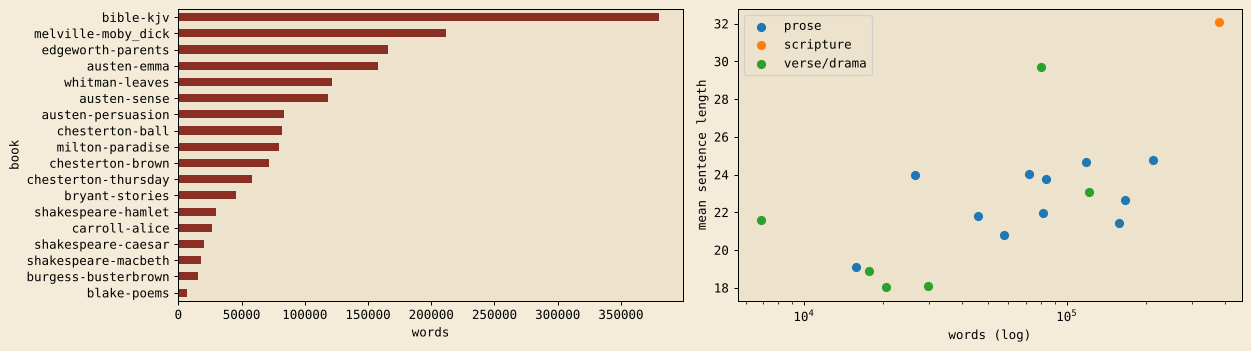

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
corpus.set_index('book').words.plot.barh(ax=ax[0], color='#8B2E24'); ax[0].set_xlabel('words'); ax[0].invert_yaxis()
for g, d in corpus.groupby('genre'):
    ax[1].scatter(d.words, d.mean_sentence_words, label=g, s=40)
ax[1].set_xscale('log'); ax[1].set_xlabel('words (log)'); ax[1].set_ylabel('mean sentence length'); ax[1].legend()
plt.tight_layout(); plt.show()

**Bias note.** Authors with several books (Austen, Chesterton, Shakespeare) are all 19th-century or earlier and genre-homogeneous, so "same author" is confounded with "same era and genre" in notebook 02. Verse and scripture have very different sentence statistics and are excluded from the prose experiments.

## Function-word profiles (computed by the shipped JavaScript stylometry engine)

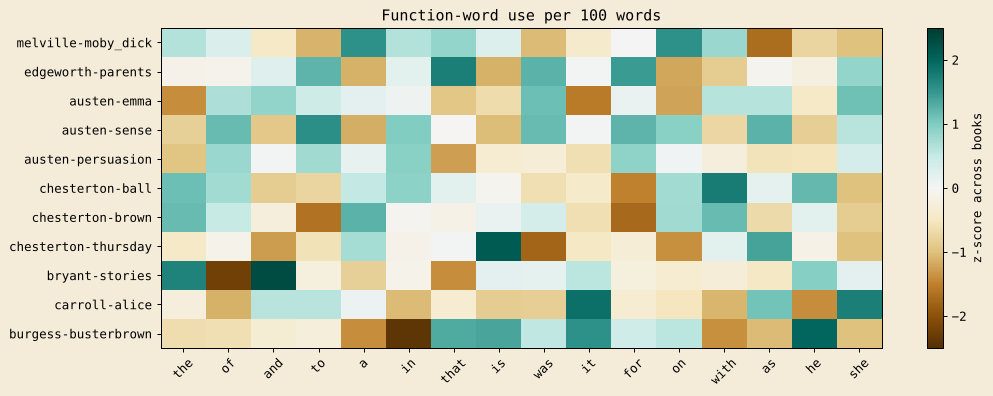

In [4]:
prose = corpus[corpus.genre == 'prose'].book.tolist()
feats = run_js([{'op': 'styleFeatures', 'text': ' '.join(load_book(b + '.txt').split()[5000:9000])} for b in prose])
fw = pd.DataFrame(feats, index=prose)[[c for c in feats[0] if c.startswith('fw_')][:16]]
fw.columns = [c[3:] for c in fw.columns]
fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow((fw - fw.mean()) / fw.std(), cmap='BrBG', aspect='auto', vmin=-2.5, vmax=2.5)
ax.set_xticks(range(len(fw.columns)), fw.columns, rotation=45); ax.set_yticks(range(len(fw)), fw.index)
plt.colorbar(im, label='z-score across books'); plt.title('Function-word use per 100 words'); plt.tight_layout(); plt.show()

## Synthetic image data

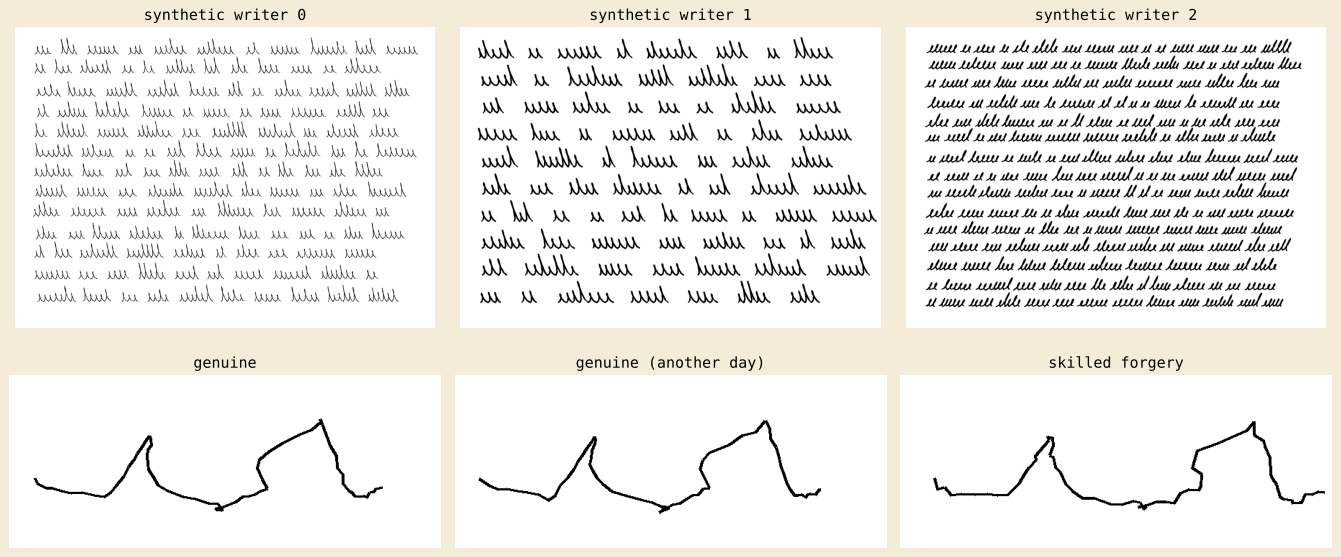

In [5]:
rng = random.Random(1)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for k, ax in enumerate(axes[0]):
    p = WORK / f'explore_writer{k}.png'; draw_handwriting(p, writer_params(rng), seed=k); ax.imshow(Image.open(p), cmap='gray'); ax.set_title(f'synthetic writer {k}'); ax.axis('off')
base = signature_base(rng)
for k, (ax, (var, dist, name)) in enumerate(zip(axes[1], [(1.4, 0, 'genuine'), (1.4, 0, 'genuine (another day)'), (2.6, 0.07, 'skilled forgery')])):
    p = WORK / f'explore_sig{k}.png'; draw_signature(p, base, seed=10 + k, variation=var, distort=dist); ax.imshow(Image.open(p), cmap='gray'); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

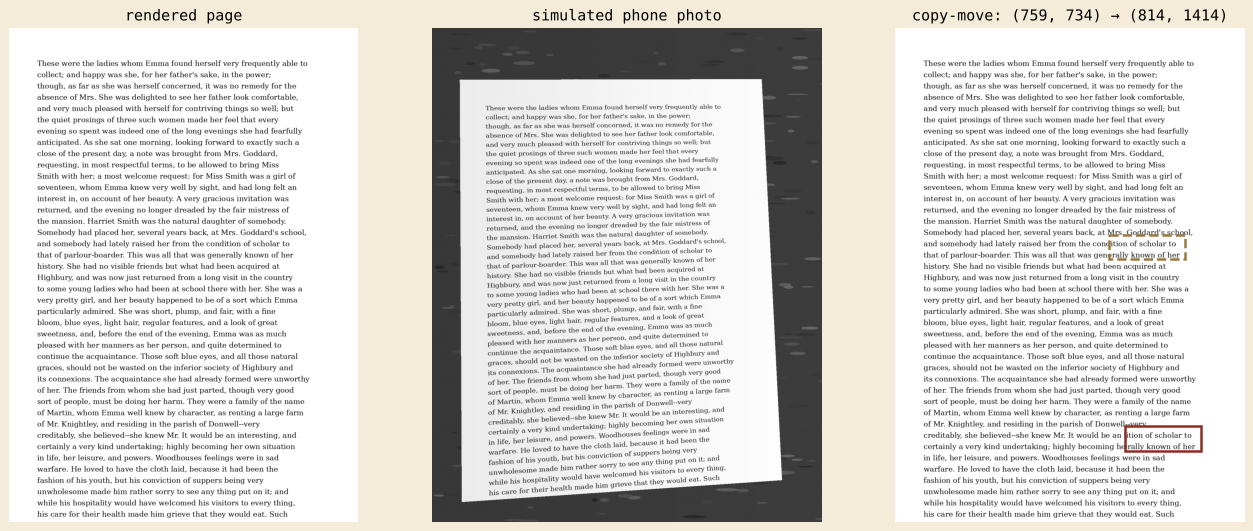

In [6]:
page = render_text_page(' '.join(sentences(load_book('austen-emma.txt'))[200:230]))
photo, corners = photograph_page(page, random.Random(4))
tampered, src, dst = paste_region(page, random.Random(5))
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, im, t in zip(ax, [page, photo, tampered], ['rendered page', 'simulated phone photo', f'copy-move: {src[:2]} → {dst[:2]}']):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis('off')
ax[2].add_patch(plt.Rectangle(src[:2], src[2], src[3], fill=False, ec='#9A7B3F', lw=2, ls='--'))
ax[2].add_patch(plt.Rectangle(dst[:2], dst[2], dst[3], fill=False, ec='#8B2E24', lw=2))
plt.tight_layout(); plt.show()

## Test fixtures

`tools/make_fixtures.py` also writes the controlled files used by the unit and browser tests, including harmless "attack" files (an MZ header named `.pdf`, ZIP bombs, traversal archives, a PNG declaring 50,000 × 50,000 pixels).

In [7]:
fx = ROOT / 'tests' / 'fixtures'
pd.DataFrame([dict(file=p.name, kb=round(p.stat().st_size / 1024, 1)) for p in sorted(fx.iterdir()) if p.is_file()]).set_index('file').T

file,archive.zip,binary.txt,corrupt.pdf,empty.txt,entity_expansion.docx,essay_a.pdf,essay_a.txt,essay_b.docx,essay_b.txt,essay_c.txt,...,sig_person1_a.png,sig_person1_b.png,sig_person2_a.png,symlink.docx,tampered_copy_move.png,too_many_entries.docx,too_many_pages.pdf,traversal.docx,truncated.png,zip_bomb.docx
kb,0.1,1.0,0.1,0.0,0.6,3.7,1.1,36.1,0.9,0.7,...,2.0,2.0,1.7,0.7,225.5,113.3,58.0,0.6,3.9,60.4
